# 06 — BFM replication (Blanchet et al. 2022)

Skeleton to replicate BFM for Chile 2017 and apply to CASEN 2022. Full Stata reference: `https://github.com/ignacio-flores/bfmcorr` + `gpinter` (`https://wid.world/gpinter/`).
Fractal bins viz (Figure 3) is kept from the previous draft; BFM steps are TODO wired to `source/bfm.py`.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from pathlib import Path
from utils import load_root

ROOT = load_root()
from source.shares import weighted_shares
from source.sii import load_sii_pub_total, sii_for_at
from source.figures import plot_bfm_fractal_bins, save_fig
from source.bfm import interpolate_tax_tabulation, estimate_merging_point, calibrate_weights

%load_ext autoreload
%autoreload 2

[utils] Project root loaded successfully: /home/choroy/Documents/doctorado/S4/ENECO894/problem-set


## 0. Fractal bins


This cell visualizes the **fractal binning** of Section~\ref{sec:bfm} (Eq.~\ref{eq:theta-Theta}--\ref{eq:merging-point}, Figure~\ref{fig:fractal} in `03.tex`).
It calls `plot_bfm_fractal_bins` from `source/figures.py` (the 99 bins $0$--$99\%$ plus 9 bins $\times 0.1/0.01/0.001$ pp) and saves `figures/p3/bfm_fractal_bins.pdf` used in the report.
Pedagogically: each row zooms into the red-hatched tail of the row above — resolution grows where $\theta(y)$ is expected to fall.


/tmp/ipykernel_93882/1645219120.py:3: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.32, 0, 0.96, 0.92])


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/p3/bfm_fractal_bins.pdf


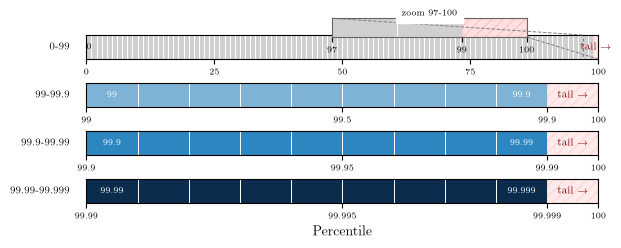

In [2]:
fig = plt.figure(figsize=(8, 2))
fig, axes = plot_bfm_fractal_bins(fig)
plt.tight_layout(rect=[0.32, 0, 0.96, 0.92])
save_fig(ROOT / "figures/p3/bfm_fractal_bins.pdf", fig)
plt.show()


## 1. Load inputs for Chile 2017 and 2022

- **Survey:** `data/processed/casen_2017_hh.parquet` and `casen_2022_hh.parquet` (from `05_data_exploration.ipynb`, one row per `folio+hogar` via `to_household`)
  - `ytotcorh` = total household income (corrected for non-response)
  - `expr` = expansion factor (survey weight)
  - `folio+hogar` = household identifier (one row per household)
- **Tax tabulation:** SII brackets from `data/SII/PUB_Total.xlsb` (SII, personas naturales, 2005--2024) — Consolidated `cons_n`/`cons_renta` by UTA bracket, filtered to commercial years 2017 (AT 2018) and 2022 (AT 2023) via `load_sii_pub_total` / `sii_for_at` in `source/sii.py`. No Flores et al. (2020) tabulation was used (the `bfmcorr` repo only contained the Brazil example).


**Load survey inputs**

We use the household-level CASEN files built in `05_data_exploration.ipynb` where,

- `ytotcorh` = total household income, 
- `expr` = expansion factor, 
- one row per `folio+hogar` via `to_household`

These are the $y_i, d_i$ in Eq. 14


In [3]:
hh17 = pd.read_parquet(ROOT / "data/processed/casen_2017_hh.parquet")
hh22 = pd.read_parquet(ROOT / "data/processed/casen_2022_hh.parquet")
print(hh17.shape, hh22.shape)
hh17.head()


(70948, 7) (72053, 7)


,folio,hogar,ytotcorh,expr,tot_per_h,region,area
0,1.101100e+11,1,250000,23,1,1,1
1,1.101100e+11,1,211091,29,1,1,1
2,1.101100e+11,1,593500,46,2,1,1
3,1.101100e+11,1,341667,42,3,1,1
4,1.101100e+11,1,463333,32,2,1,1


**Build tax tabulations** — Parses the double header (rows 6--7) of `PUB_Total.xlsb` (SII 2005--2024) into tidy `cons_n`/`cons_renta` (Consolidated). 

We filter commercial years 2017 (AT 2018) and 2022 (AT 2023) with `sii_for_at` and save `data/SII/sii_2017_tabulation.csv` for `bfmcorr`/`gpinter`. These $w_k$ and brackets define the $y_k$ in the histogram.


In [4]:
# Build BFM tax files from PUB_Total.xlsb (no manual CSV needed)
raw, cleaned = load_sii_pub_total(ROOT / 'data/SII/PUB_Total.xlsb')

# Save BFM-ready CSVs for AT 2018 (com. 2017) and AT 2023 (com. 2022)

out_dir = ROOT / "data/SII"
out_dir.mkdir(parents=True, exist_ok=True)

for at_com in [2017, 2022]:
    df_at = sii_for_at(cleaned, at_com)

    # BFM expects brackets with threshold, n, total income
    bfm = df_at[["tramo", "cons_n", "cons_renta"]]
    bfm = bfm.rename(columns={"tramo":"bracket",
                              "cons_n":"n","cons_renta":
                              "total_income_mm"})
    
    # save csv
    csv = out_dir / f"sii_{at_com}_tabulation.csv"
    bfm.to_csv(csv, index=False)
    
    print(f"saved {csv} -> {len(bfm)} brackets")
    display(bfm.head())

tax2017 = sii_for_at(cleaned, 2017)
tax2022 = sii_for_at(cleaned, 2022)


saved /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/data/SII/sii_2017_tabulation.csv -> 7 brackets


,bracket,n,total_income_mm
104,"Tramo 1 - 0 a 13,5 UTA (Exento)",7521748,20780170.0
105,"Tramo 2 - 13,5 a 30 UTA (Tasa 4%)",1602936,17606393.3
106,Tramo 3 - 30 a 50 UTA (Tasa 8%),451646,9675282.0
107,"Tramo 4 - 50 a 70 UTA (Tasa 13,5%)",171242,5668327.8
108,Tramo 5 - 70 a 90 UTA (Tasa 23%),85817,3818661.2


saved /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/data/SII/sii_2022_tabulation.csv -> 8 brackets


,bracket,n,total_income_mm
141,"Tramo 1 - 0 a 13,5 UTA (Exento)",8445792,32634187.8
142,"Tramo 2 - 13,5 a 30 UTA (Tasa 4%)",1950483,27927090.1
143,Tramo 3 - 30 a 50 UTA (Tasa 8%),539187,15035930.4
144,"Tramo 4 - 50 a 70 UTA (Tasa 13,5%)",196432,8461577.9
145,Tramo 5 - 70 a 90 UTA (Tasa 23%),93151,5390994.0


## 2. gpinter interpolation + merging point y*



**Estimate $y^*$** — `estimate_merging_point(y,w,tax_n)` computes $$\tilde\theta_k=\text{share}_{s,k}/w_k$$ share survey / share tax ($width_k$ cancels), $$\hat\Theta(y)=(1-\hat F_s)/(1-\hat F_t),$$ then smooths $\tilde\theta$ to $\hat\theta$ via antitonic regression $$\min \sum w_k(\hat\theta_k-\tilde\theta_k)^2$$ s.t. decreasing, PAVA. $$k^*=\min\{k:\hat\theta_k<\hat\Theta_k\}$$ gives $y^*=y_{k^*}$. The printed `tilde`/`theta_hat` let you verify monotonicity.


In [5]:

# Use household income (ytotcorh) and SII cons_n
for name, hh, at in [("2017", hh17, 2017), ("2022", hh22, 2022)]:
    y = hh["ytotcorh"].values
    w = hh["expr"].values
    tax_df = sii_for_at(cleaned, at)
    tax = tax_df["cons_n"].values
    tramos = tax_df["tramo"].tolist()

    y_star, tilde, theta_hat, Theta_hat, yk = estimate_merging_point(y, w, tax, tax_tramos=tramos, at_comercial=at)
    
    print(f"{name}: y* = {y_star:,.0f} CLP")
    print(f"  tilde={tilde.round(2).tolist()}")
    print(f"  theta_hat={theta_hat.round(2).tolist()}")


2017: y* = 67,200,000 CLP
  tilde=[1.32, 0.04, 0.01, 0.01, 0.0, 0.0, 0.0]
  theta_hat=[1.32, 0.04, 0.01, 0.01, 0.0, 0.0, 0.0]
2022: y* = 49,000,000 CLP
  tilde=[1.34, 0.04, 0.01, 0.0, 0.0, 0.01, 0.0, 0.0]
  theta_hat=[1.34, 0.04, 0.01, 0.0, 0.0, 0.0, 0.0, 0.0]


## 3. Calibration + expanding support


**Calibration (reweighting)** — Section~\ref{sec:bfm-reweighting} (Eq.~\ref{eq:calibration}) in `03.tex`.
`calibrate_weights(y,w,y^*,tax_n, alpha=5)` implements truncated linear calibration: it finds $k^*$ for $y^*$, computes $\text{tax\_share}_{\ge k^*}$ vs $\text{survey\_share}_{\ge y^*}$, sets `factor_above = tax_share_above / share_s_above` (clipped to $[1/\alpha,\alpha]$) and `factor_below` to preserve total population, producing $w_i^{cal}$. This matches the tax mass above $y^*$ while keeping demographic totals (cf. `03.tex` Algorithm~\ref{alg:bfm} Step 2).


In [6]:
# Calibrate weights (uniform rescaling above y*)
for name, hh, at in [("2017", hh17, 2017), ("2022", hh22, 2022)]:
    y = hh["ytotcorh"].values
    w = hh["expr"].values
    tax_df = sii_for_at(cleaned, at)
    tax = tax_df["cons_n"].values
    tramos = tax_df["tramo"].tolist()
    y_star, *_ = estimate_merging_point(y, w, tax, tax_tramos=tramos, at_comercial=at)
    w_cal = calibrate_weights(y, w, y_star, tax, alpha=5)
    hh["w_bfm"] = w_cal
    print(f"{name}: y*={y_star:,.0f}, mean w factor above={w_cal[y>=y_star].mean()/w[y>=y_star].mean():.2f}")


2017: y*=67,200,000, mean w factor above=5.00
2022: y*=49,000,000, mean w factor above=5.00


## 4. Compare raw vs BFM top shares (to fill Table in 03.tex)


**Compare inequality** — Algorithm~\ref{alg:bfm} Step 4 and Section~\ref{sec:bfm-data}.
`weighted_shares` (from `source/shares.py`) computes bottom 50\%, top 10\% and top 1\% on the same $y=$ `ytotcorh` with `expr` (raw) vs `w_bfm` (BFM). The table quantifies how the reweighting shifts mass to the top, as discussed in the report's Data section (Figures~\ref{fig:casen-income}--\ref{fig:sii-comparison}).


In [7]:

rows=[]
for name, hh in [("2017 raw", hh17), ("2017 BFM", hh17), ("2022 raw", hh22), ("2022 BFM", hh22)]:
    is_bfm = "BFM" in name
    wcol = "w_bfm" if is_bfm else "expr"
    # weighted_shares expects DataFrame with income and weight
    s = weighted_shares(hh, wealth_col="ytotcorh", weight_col=wcol)
    rows.append({"sample": name, **s})
pd.DataFrame(rows)


,sample,bottom50,top10,top1
0,2017 raw,0.231388,0.306494,0.049966
1,2017 BFM,0.210136,0.359168,0.099741
2,2022 raw,0.224400,0.332959,0.076616
3,2022 BFM,0.222483,0.338490,0.084778


## 5. Figure 6e emulation — Chile 2015 (for the report)

Synthetic emulation of BFM (2022) Figure 6e as described: grey dots $\theta(y)$, blue antitonic, red $\Theta(y)$, green moving avg., blue dashed extrapolation, merging point ~P83.5.


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/p3/bfm_theta_Theta_real.pdf


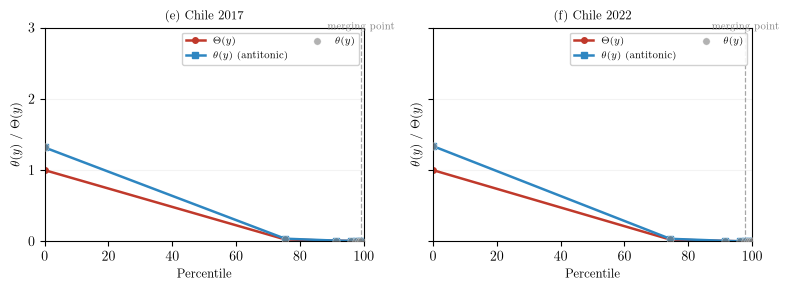

In [12]:
# Real BFM diagnostic — same style as Fig 6e but with our CASEN+SII data (2017 and 2022)
from source.figures import plot_bfm_theta_Theta_real
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
for ax, (name, hh, at) in zip(axes, [("(e) Chile 2017", hh17, 2017), ("(f) Chile 2022", hh22, 2022)]):
    y = hh["ytotcorh"].values
    w = hh["expr"].values
    tax_df = sii_for_at(cleaned, at)
    y_star, tilde, theta_hat, Theta_hat, yk = estimate_merging_point(y, w, tax_df["cons_n"].values, tax_tramos=tax_df["tramo"].tolist(), at_comercial=at)
    plot_bfm_theta_Theta_real(fig, ax, tilde, theta_hat, Theta_hat, yk, tax_df["cons_n"].values/tax_df["cons_n"].sum(), title=name)
plt.tight_layout()
save_fig(ROOT / "figures/p3/bfm_theta_Theta_real.pdf", fig)
plt.show()
